# 05 · Early-Warning Churn Model

**Purpose:** Predict, at day 31, which still-subscribed customers will cancel in the next 90 days, using only information available at day 31. Compare two models against a simple rule baseline and report honestly how much value the model adds.

**Inputs:** `data/processed/subscriptions_model.csv`, `data/processed/customer_features.csv`
**Outputs:** `data/processed/risk_scores.csv`, `reports/figures/06_model_evaluation.png`, `reports/figures/07_feature_importance.png`

**Method notes**
- **Prediction point:** day 31. **Target:** cancels within days 32-121.
- **Only customers with a fully known outcome** are used (signed up on or before 2025-09-01).
- **Time-based split:** train on earlier signups, test on later ones.
- **No leakage:** features come only from the first month. `usage_stopped_early` is excluded because it is learned from usage after day 31.
- **Metrics:** ROC-AUC, PR-AUC (random guessing = the churn rate), and top-10% lift.

In [ ]:
%pip install scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

PROC = Path("../data/processed")
REPORTS = Path("../reports")
FIG = REPORTS / "figures"

subs = pd.read_csv(PROC / "subscriptions_model.csv", parse_dates=["signup_date", "churn_date", "end_date"])
feats = pd.read_csv(PROC / "customer_features.csv").drop(columns="engagement")
d = subs.merge(feats, on="customer_id")
d["engagement_band"] = pd.cut(d.first_workouts, [-1, 0, 2, 5, 1000], labels=["0", "1-2", "3-5", "6+"]).astype(str)
print(d.shape)

(4200, 29)


Defining the prediction problem: at day 31, will a still-subscribed customer cancel within the next 90 days? We keep only customers whose outcome is fully known.

In [4]:
LANDMARK = 31          # prediction point: end of the first month
HORIZON = 90           # we predict cancellation in days 32-121
DATA_END = pd.Timestamp("2025-12-31")
latest_signup = DATA_END - pd.offsets.Day(LANDMARK + HORIZON)    # later signups haven't had 121 days yet

lm = d[d.duration_days > LANDMARK].copy()
lm["label"] = ((lm.event == 1) & (lm.duration_days <= LANDMARK + HORIZON)).astype(int)
lm["observable"] = lm.signup_date <= latest_signup

data = lm[lm.observable].copy()
print("still subscribed at day 31                     :", len(lm))
print("outcome not yet known (signed up after", latest_signup.date(), "):", (~lm.observable).sum())
print("modelling set                                  :", len(data))
print("cancelled within 90 days of day 31             :", f"{data.label.mean():.1%}")
print("  monthly plans:", f"{data[data.plan_type == 'monthly'].label.mean():.1%}",
      "| annual plans:", f"{data[data.plan_type == 'annual'].label.mean():.1%}")

still subscribed at day 31                     : 3921
outcome not yet known (signed up after 2025-09-01 ): 554
modelling set                                  : 3367
cancelled within 90 days of day 31             : 17.2%
  monthly plans: 26.3% | annual plans: 2.4%


Choosing the features and proving none of them leaks future information.

In [5]:
NUMERIC = ["first_workouts", "first_tickets", "first_classes"]
CATEGORICAL = ["plan_type", "plan_tier", "acquisition_channel", "primary_device", "age_group", "engagement_band"]
FEATURES = NUMERIC + CATEGORICAL

FORBIDDEN = {
    "event / churned / churn_date / cancel_reason": "the outcome itself",
    "duration_days / tenure_days / end_date": "built from the cancel date",
    "usage_stopped_early": "known only by watching usage AFTER day 31",
    "usage_months_expected / usage_months_observed": "built from usage AFTER day 31",
}
assert not set(FEATURES) & {"event", "churned", "churn_date", "cancel_reason", "duration_days", "tenure_days",
                            "end_date", "usage_stopped_early", "usage_months_expected", "usage_months_observed", "label"}

print("features used (all known by day 31):", FEATURES)
print("\nexcluded to avoid leakage:")
for name, reason in FORBIDDEN.items():
    print(f"  - {name}: {reason}")

features used (all known by day 31): ['first_workouts', 'first_tickets', 'first_classes', 'plan_type', 'plan_tier', 'acquisition_channel', 'primary_device', 'age_group', 'engagement_band']

excluded to avoid leakage:
  - event / churned / churn_date / cancel_reason: the outcome itself
  - duration_days / tenure_days / end_date: built from the cancel date
  - usage_stopped_early: known only by watching usage AFTER day 31
  - usage_months_expected / usage_months_observed: built from usage AFTER day 31


Splitting by signup date (train on earlier customers, test on later ones) and checking that the churn rate is stable over time.

In [6]:
SPLIT_DATE = pd.Timestamp("2025-05-01")
train = data[data.signup_date < SPLIT_DATE]
test = data[data.signup_date >= SPLIT_DATE]

print(f"train: {len(train)} customers, signed up {train.signup_date.min().date()} to {train.signup_date.max().date()}, churn rate {train.label.mean():.1%}")
print(f"test : {len(test)} customers, signed up {test.signup_date.min().date()} to {test.signup_date.max().date()}, churn rate {test.label.mean():.1%}")

by_month = data.groupby(data.signup_date.dt.to_period("M")).label.agg(customers="size", churn_rate="mean")
by_month["churn_rate"] = (by_month.churn_rate * 100).round(1)
by_month.T

train: 2276 customers, signed up 2024-07-01 to 2025-04-30, churn rate 16.6%
test : 1091 customers, signed up 2025-05-01 to 2025-09-01, churn rate 18.4%


signup_date,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09
customers,162.0,178.0,207.0,236.0,233.0,271.0,236.0,234.0,267.0,252.0,266.0,274.0,263.0,281.0,7.0
churn_rate,15.4,15.2,16.9,16.5,13.7,17.7,22.5,16.2,17.2,13.9,19.5,18.6,17.5,17.8,28.6


Building and training two models (logistic regression and gradient boosting) on the training set only.

In [7]:
def make_pipeline(model, scale):
    prep = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ])
    return Pipeline([("prep", prep), ("model", model)])

models = {
    "logistic regression": make_pipeline(LogisticRegression(max_iter=1000), scale=True),
    "gradient boosting": make_pipeline(
        HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                       l2_regularization=1.0, random_state=42),
        scale=False),
}
for name, m in models.items():
    m.fit(train[FEATURES], train.label)
print("trained:", list(models))

trained: ['logistic regression', 'gradient boosting']


Evaluating on the test set against a simple rule baseline, using ROC-AUC, PR-AUC and top-10% lift.

In [8]:
def top_decile(y, p):
    k = int(np.ceil(len(y) * 0.10))
    top = np.argsort(-p)[:k]                       # the 10% of customers with the highest risk
    caught = y.values[top]
    return caught.mean() / y.mean(), caught.sum() / y.sum()

def evaluate(y, scores):
    lift, capture = top_decile(y, scores)
    return {"ROC-AUC": roc_auc_score(y, scores), "PR-AUC": average_precision_score(y, scores),
            "top-10% lift": lift, "top-10% capture": capture}

def rule_score(df):                                 # no model: monthly plan and few workouts = risky
    return ((df.plan_type == "monthly") * 10 - df.first_workouts).values

scores = {"simple rule": rule_score(test)}
for name, m in models.items():
    scores[name] = m.predict_proba(test[FEATURES])[:, 1]

results = pd.DataFrame({k: evaluate(test.label, v) for k, v in scores.items()}).T
print("test customers:", len(test), "| churn rate:", round(test.label.mean(), 3), "(PR-AUC of random guessing)")
results.round(3)

test customers: 1091 | churn rate: 0.184 (PR-AUC of random guessing)


,ROC-AUC,PR-AUC,top-10% lift,top-10% capture
simple rule,0.780,0.398,2.467,0.249
logistic regression,0.791,0.478,2.763,0.279
gradient boosting,0.778,0.444,2.911,0.294


Repeating the evaluation on monthly plans only, since annual customers almost never cancel in this window.

In [9]:
tm = test[test.plan_type == "monthly"]
monthly_scores = {"simple rule": rule_score(tm)}
for name, m in models.items():
    monthly_scores[name] = m.predict_proba(tm[FEATURES])[:, 1]

print("monthly test customers:", len(tm), "| churn rate:", round(tm.label.mean(), 3))
pd.DataFrame({k: evaluate(tm.label, v) for k, v in monthly_scores.items()}).T.round(3)

monthly test customers: 673 | churn rate: 0.27


,ROC-AUC,PR-AUC,top-10% lift,top-10% capture
simple rule,0.686,0.414,1.903,0.192
logistic regression,0.716,0.503,2.284,0.231
gradient boosting,0.685,0.465,2.230,0.225


Picking logistic regression as the final model and checking its decile table: does higher predicted risk really mean more cancellations?

In [10]:
final_name = "logistic regression"
final = models[final_name]

tt = test.copy()
tt["risk"] = scores[final_name]
tt["decile"] = pd.qcut(tt.risk.rank(method="first", ascending=False), 10, labels=range(1, 11))   # 1 = highest risk

dec = tt.groupby("decile", observed=True).agg(customers=("label", "size"),
                                              avg_predicted=("risk", "mean"),
                                              actual_churn=("label", "mean"))
dec["lift"] = dec.actual_churn / tt.label.mean()
dec["cum_capture"] = tt.groupby("decile", observed=True).label.sum().cumsum() / tt.label.sum()
dec.round(3)

,customers,avg_predicted,actual_churn,lift,cum_capture
decile,,,,,
1,110,0.516,0.509,2.763,0.279
2,109,0.335,0.394,2.141,0.493
3,109,0.274,0.303,1.643,0.657
4,109,0.229,0.174,0.946,0.751
5,109,0.157,0.165,0.896,0.841
6,109,0.086,0.110,0.598,0.900
7,109,0.032,0.083,0.448,0.945
8,109,0.015,0.046,0.249,0.970
9,109,0.010,0.037,0.199,0.990


Plotting the gains chart (how many churners we reach) and the calibration chart (are the predicted probabilities honest?).

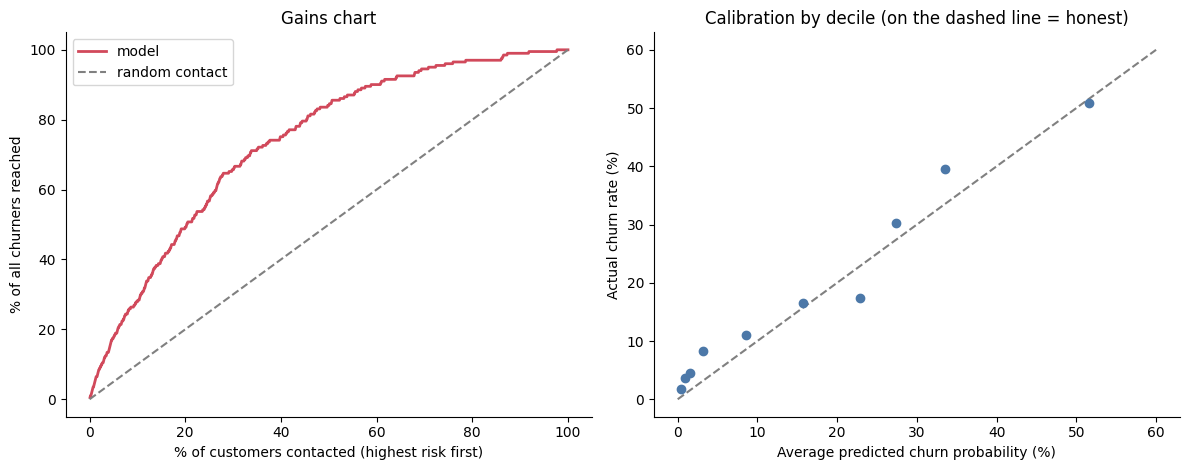

In [11]:
order = tt.sort_values("risk", ascending=False)
gain = order.label.cumsum() / order.label.sum()
x = np.arange(1, len(order) + 1) / len(order)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].plot(x * 100, gain * 100, color="#D1495B", lw=2, label="model")
axes[0].plot([0, 100], [0, 100], "--", color="grey", label="random contact")
axes[0].set_xlabel("% of customers contacted (highest risk first)")
axes[0].set_ylabel("% of all churners reached")
axes[0].set_title("Gains chart")
axes[0].legend()

axes[1].scatter(dec.avg_predicted * 100, dec.actual_churn * 100, color="#4C78A8", zorder=3)
axes[1].plot([0, 60], [0, 60], "--", color="grey")
axes[1].set_xlabel("Average predicted churn probability (%)")
axes[1].set_ylabel("Actual churn rate (%)")
axes[1].set_title("Calibration by decile (on the dashed line = honest)")

fig.tight_layout()
fig.savefig(FIG / "06_model_evaluation.png", dpi=150)
plt.show()

Finding which features the model relies on, by measuring how much PR-AUC drops when each one is shuffled.

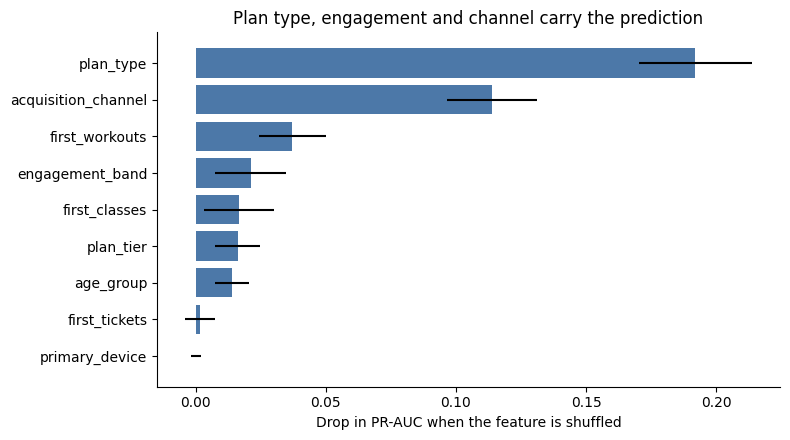

,feature,pr_auc_drop,std
0,plan_type,0.1919,0.0218
1,acquisition_channel,0.1139,0.0174
2,first_workouts,0.0371,0.0128
3,engagement_band,0.0211,0.0137
4,first_classes,0.0165,0.0134
5,plan_tier,0.0161,0.0087
6,age_group,0.0140,0.0066
7,first_tickets,0.0016,0.0056
8,primary_device,-0.0000,0.0020


In [12]:
imp = permutation_importance(final, test[FEATURES], test.label, scoring="average_precision",
                             n_repeats=20, random_state=42)
importance = (pd.DataFrame({"feature": FEATURES, "pr_auc_drop": imp.importances_mean, "std": imp.importances_std})
              .sort_values("pr_auc_drop", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 4.5))
plot = importance.iloc[::-1]
ax.barh(plot.feature, plot.pr_auc_drop, xerr=plot["std"], color="#4C78A8")
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.set_title("Plan type, engagement and channel carry the prediction")
fig.tight_layout()
fig.savefig(FIG / "07_feature_importance.png", dpi=150)
plt.show()

importance.round(4)

Quantifying uncertainty with a bootstrap on the test set, and testing whether the model really beats the rule and whether boosting beats logistic regression.

In [13]:
rng = np.random.default_rng(42)
y = test.label.values
store = {name: [] for name in scores}

for _ in range(500):
    idx = rng.integers(0, len(y), len(y))
    if y[idx].sum() == 0:
        continue
    for name, s in scores.items():
        store[name].append((roc_auc_score(y[idx], s[idx]), average_precision_score(y[idx], s[idx])))

def rng95(v):
    return f"{np.mean(v):.3f} ({np.percentile(v, 2.5):.3f} to {np.percentile(v, 97.5):.3f})"

table = {name: {"ROC-AUC": rng95(np.array(v)[:, 0]), "PR-AUC": rng95(np.array(v)[:, 1])} for name, v in store.items()}
print(pd.DataFrame(table).T.to_string())

lr, gb, rule = (np.array(store[k])[:, 1] for k in ["logistic regression", "gradient boosting", "simple rule"])
print("\nPR-AUC difference, logistic regression minus simple rule :", rng95(lr - rule))
print("PR-AUC difference, gradient boosting minus logistic reg. :", rng95(gb - lr))

                                    ROC-AUC                  PR-AUC
simple rule          0.781 (0.751 to 0.812)  0.401 (0.344 to 0.461)
logistic regression  0.791 (0.759 to 0.824)  0.481 (0.409 to 0.550)
gradient boosting    0.779 (0.746 to 0.811)  0.448 (0.378 to 0.517)

PR-AUC difference, logistic regression minus simple rule : 0.080 (0.028 to 0.130)
PR-AUC difference, gradient boosting minus logistic reg. : -0.033 (-0.054 to -0.013)


Scoring every customer still subscribed at day 31 and saving the risk scores and risk bands for the dashboard.

In [14]:
lm["risk_score"] = final.predict_proba(lm[FEATURES])[:, 1]
lm["split"] = np.where(~lm.observable, "recent", np.where(lm.signup_date < SPLIT_DATE, "train", "test"))
lm["risk_decile"] = pd.qcut(lm.risk_score.rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)
lm["risk_band"] = np.select([lm.risk_decile == 1, lm.risk_decile <= 3], ["high", "medium"], default="low")

cols = ["customer_id", "signup_date", "plan_type", "plan_tier", "acquisition_channel", "monthly_price",
        "first_workouts", "risk_score", "risk_decile", "risk_band", "split", "label", "observable", "event"]
lm[cols].to_csv(PROC / "risk_scores.csv", index=False)

print("scored customers:", len(lm), "|", lm.split.value_counts().to_dict())
print("\nCustomers STILL SUBSCRIBED at the end of the data, by risk band:")
active = lm[lm.event == 0]
(active.groupby("risk_band")
       .agg(customers=("customer_id", "size"), avg_risk=("risk_score", "mean"), monthly_revenue=("monthly_price", "sum"))
       .reindex(["high", "medium", "low"]).round(2))

scored customers: 3921 | {'train': 2276, 'test': 1091, 'recent': 554}

Customers STILL SUBSCRIBED at the end of the data, by risk band:


,customers,avg_risk,monthly_revenue
risk_band,,,
high,147,0.50,2724.53
medium,372,0.31,6872.28
low,1913,0.07,29897.62


Cross-checking: the model never saw the "usage stopped early" flag, so how many of those 139 customers does it place in the high-risk band?

In [15]:
flagged = lm[lm.usage_stopped_early]
print("flagged customers (active, usage stopped after month 1):", len(flagged))
print(flagged.risk_band.value_counts().reindex(["high", "medium", "low"]).to_dict())

others = lm[(lm.event == 0) & ~lm.usage_stopped_early]
print("\nshare of customers in the high-risk band")
print(f"  flagged customers       : {(flagged.risk_band == 'high').mean():.1%}")
print(f"  other active customers  : {(others.risk_band == 'high').mean():.1%}")

flagged customers (active, usage stopped after month 1): 139
{'high': 37, 'medium': 53, 'low': 49}

share of customers in the high-risk band
  flagged customers       : 26.6%
  other active customers  : 4.8%


### Phase 5 results

| Model (test set) | ROC-AUC | PR-AUC | Top-10% lift |
|---|---:|---:|---:|
| Random guessing | 0.50 | 0.184 | 1.0 |
| Simple rule | 0.780 | 0.398 | 2.57 |
| **Logistic regression (chosen)** | **0.791** | **0.478** | **2.76** |
| Gradient boosting | 0.778 | 0.444 | 2.91 |

- **Well calibrated:** Predicted risk matches actual churn at the top (51.6% vs 50.9%).
- **Useful for targeting:** Contacting the riskiest 30% of customers reaches about 66% of churners.
- **Modest, and worth saying so:** Monthly-plan ROC-AUC is only 0.72, and the model beats a two-variable rule by about 0.08 PR-AUC. First-month data on its own has a ceiling.
- **Simplicity won:** Logistic regression beat gradient boosting, so there was no reason to add complexity.